# Análisis SVD sobre Calificaciones de Estudiantes

# Importar librerias y cargar datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, TruncatedSVD
from mpl_toolkits.mplot3d import Axes3D

import warnings
warnings.filterwarnings("ignore")

import os
os.chdir("/Users/zrgv/OneDrive/Documentos/Cientifico de datos ebac/Modulo 29")
# Cargar datos
df = pd.read_csv('Calificaciones.csv', index_col=0)
print('Datos originales:')
print(df)
print('\nForma:', df.shape)


Datos originales:
        Matematicas  Ciencias  Español  Historia  EdFisica
Lucia           7.0       6.5      9.2       8.6       8.0
Pedro           7.5       9.4      7.3       7.0       7.0
Ines            7.6       9.2      8.0       8.0       7.5
Luis            5.0       6.5      6.5       7.0       9.0
Andres          6.0       6.0      7.8       8.9       7.3
Ana             7.8       9.6      7.7       8.0       6.6
Carlos          6.3       6.4      8.2       9.0       7.2
Jose            7.9       9.7      7.5       8.0       6.0
Sonia           6.0       6.0      6.5       5.5       8.7
María           6.8       7.2      8.7       9.0       7.0

Forma: (10, 5)


# Estandarización de datos

Es fundamental estandarizar las variables antes de aplicar SVD o PCA, ya que las escalas de las calificaciones pueden variar y queremos que cada materia contribuya equitativamente.

In [2]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)
X_scaled_df = pd.DataFrame(X_scaled, index=df.index, columns=df.columns)
print('Datos estandarizados:')
print(X_scaled_df.round(3))

Datos estandarizados:
        Matematicas  Ciencias  Español  Historia  EdFisica
Lucia         0.233    -0.753    1.788     0.658     0.655
Pedro         0.787     1.146   -0.539    -0.846    -0.494
Ines          0.897     1.015    0.318     0.094     0.080
Luis         -1.983    -0.753   -1.519    -0.846     1.803
Andres       -0.875    -1.080    0.073     0.940    -0.149
Ana           1.119     1.277   -0.049     0.094    -0.953
Carlos       -0.543    -0.818    0.563     1.034    -0.264
Jose          1.230     1.342   -0.294     0.094    -1.642
Sonia        -0.875    -1.080   -1.519    -2.256     1.459
María         0.011    -0.295    1.176     1.034    -0.494


# Aplicación de SVD (Singular Value Decomposition)

Se aplica **TruncatedSVD** para reducir a 2 y 3 dimensiones. SVD descompone la matriz de datos en tres matrices: $X = U \Sigma V^T$, donde $U$ contiene las proyecciones de los estudiantes en el espacio reducido.

In [3]:
# SVD a 2 componentes
svd_2 = TruncatedSVD(n_components=2, random_state=42)
X_svd2 = svd_2.fit_transform(X_scaled)

# SVD a 3 componentes
svd_3 = TruncatedSVD(n_components=3, random_state=42)
X_svd3 = svd_3.fit_transform(X_scaled)

print('SVD 2D - Varianza explicada por componente:')
print(svd_2.explained_variance_ratio_.round(4))
print('Acumulada:', svd_2.explained_variance_ratio_.cumsum().round(4))

print('\nSVD 3D - Varianza explicada por componente:')
print(svd_3.explained_variance_ratio_.round(4))
print('Acumulada:', svd_3.explained_variance_ratio_.cumsum().round(4))

SVD 2D - Varianza explicada por componente:
[0.5783 0.3254]
Acumulada: [0.5783 0.9037]

SVD 3D - Varianza explicada por componente:
[0.5783 0.3254 0.0696]
Acumulada: [0.5783 0.9037 0.9733]


# Aplicación de PCA para comparación

PCA también se aplica en 2 y 3 componentes para comparar directamente con SVD.

In [4]:
# PCA a 2 componentes
pca_2 = PCA(n_components=2)
X_pca2 = pca_2.fit_transform(X_scaled)

# PCA a 3 componentes
pca_3 = PCA(n_components=3)
X_pca3 = pca_3.fit_transform(X_scaled)

print('PCA 2D - Varianza explicada por componente:')
print(pca_2.explained_variance_ratio_.round(4))
print('Acumulada:', pca_2.explained_variance_ratio_.cumsum().round(4))

print('\nPCA 3D - Varianza explicada por componente:')
print(pca_3.explained_variance_ratio_.round(4))
print('Acumulada:', pca_3.explained_variance_ratio_.cumsum().round(4))

PCA 2D - Varianza explicada por componente:
[0.5783 0.3254]
Acumulada: [0.5783 0.9037]

PCA 3D - Varianza explicada por componente:
[0.5783 0.3254 0.0696]
Acumulada: [0.5783 0.9037 0.9733]


# Visualización SVD en 2D

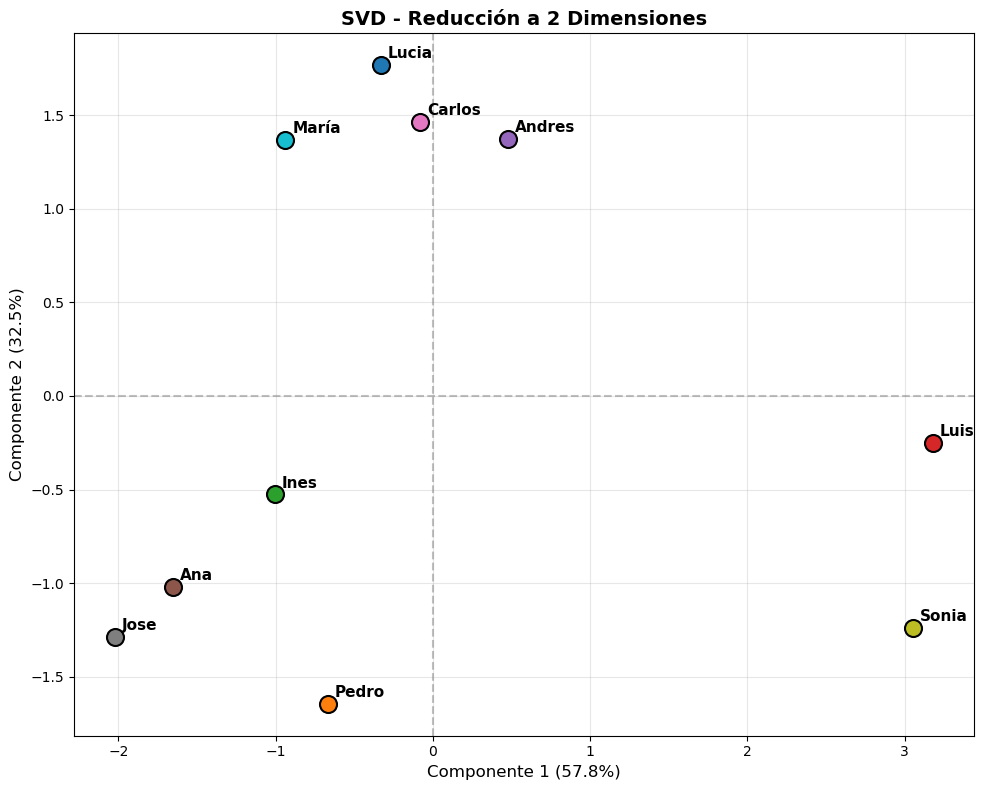

In [5]:
fig, ax = plt.subplots(figsize=(10, 8))
colors = plt.cm.tab10(np.linspace(0, 1, len(df)))

for i, name in enumerate(df.index):
    ax.scatter(X_svd2[i, 0], X_svd2[i, 1], c=[colors[i]], s=150, edgecolors='black', linewidth=1.5, zorder=3)
    ax.annotate(name, (X_svd2[i, 0], X_svd2[i, 1]), 
                xytext=(5, 5), textcoords='offset points', fontsize=11, fontweight='bold')

ax.set_xlabel(f'Componente 1 ({svd_2.explained_variance_ratio_[0]*100:.1f}%)', fontsize=12)
ax.set_ylabel(f'Componente 2 ({svd_2.explained_variance_ratio_[1]*100:.1f}%)', fontsize=12)
ax.set_title('SVD - Reducción a 2 Dimensiones', fontsize=14, fontweight='bold')
ax.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
ax.axvline(x=0, color='gray', linestyle='--', alpha=0.5)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Visualización SVD en 3D

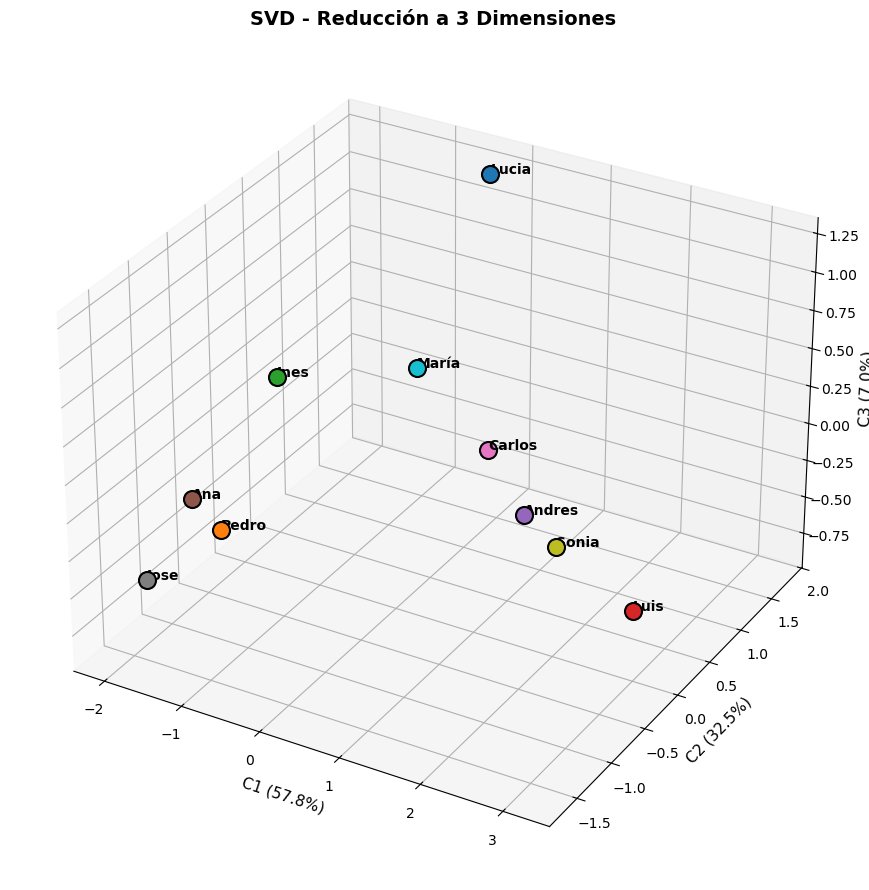

In [6]:
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

for i, name in enumerate(df.index):
    ax.scatter(X_svd3[i, 0], X_svd3[i, 1], X_svd3[i, 2], 
               c=[colors[i]], s=150, edgecolors='black', linewidth=1.5, zorder=3)
    ax.text(X_svd3[i, 0], X_svd3[i, 1], X_svd3[i, 2], name, fontsize=10, fontweight='bold')

ax.set_xlabel(f'C1 ({svd_3.explained_variance_ratio_[0]*100:.1f}%)', fontsize=11)
ax.set_ylabel(f'C2 ({svd_3.explained_variance_ratio_[1]*100:.1f}%)', fontsize=11)
ax.set_zlabel(f'C3 ({svd_3.explained_variance_ratio_[2]*100:.1f}%)', fontsize=11)
ax.set_title('SVD - Reducción a 3 Dimensiones', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Comparación directa SVD vs PCA en 2D

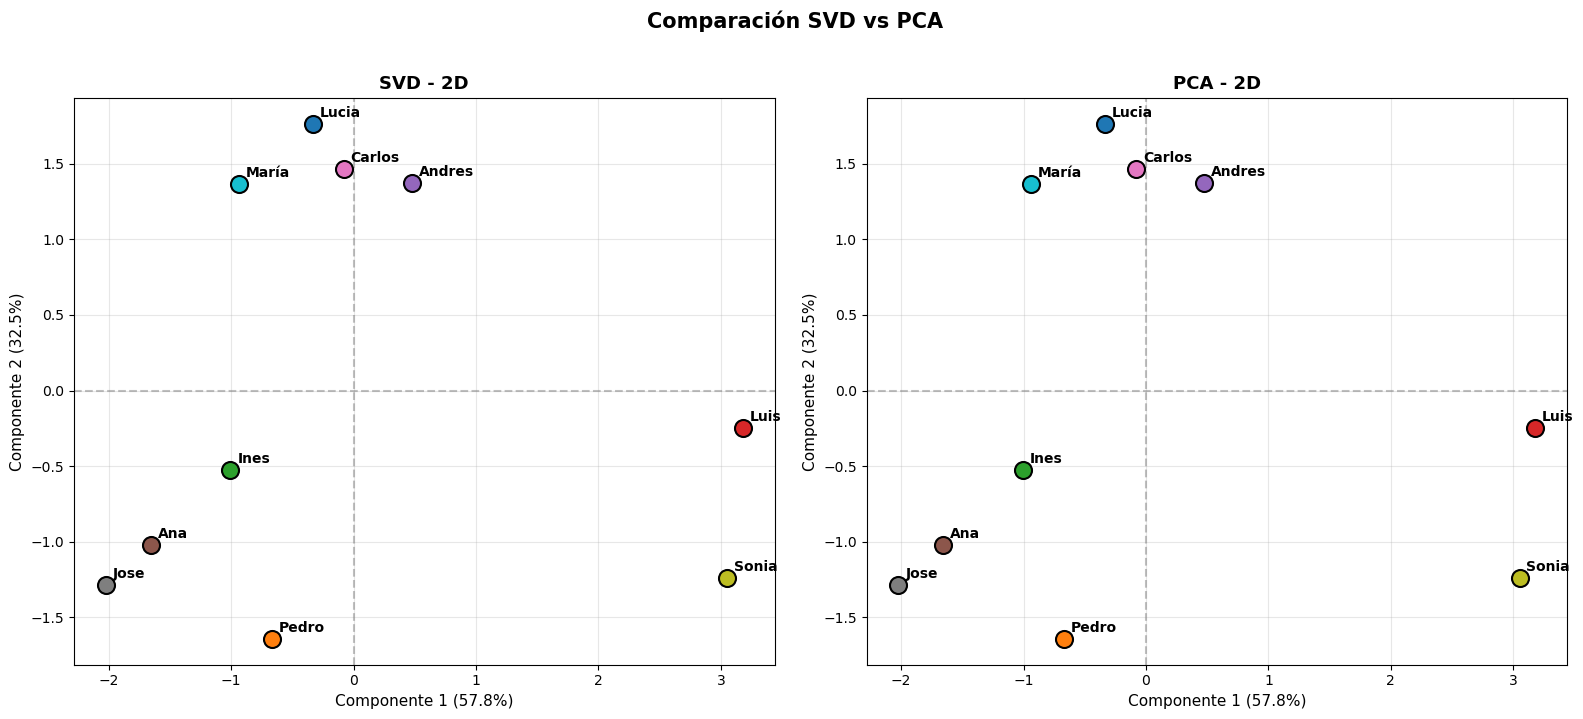

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# SVD 2D
ax1 = axes[0]
for i, name in enumerate(df.index):
    ax1.scatter(X_svd2[i, 0], X_svd2[i, 1], c=[colors[i]], s=150, edgecolors='black', linewidth=1.5, zorder=3)
    ax1.annotate(name, (X_svd2[i, 0], X_svd2[i, 1]), 
                xytext=(5, 5), textcoords='offset points', fontsize=10, fontweight='bold')
ax1.set_xlabel(f'Componente 1 ({svd_2.explained_variance_ratio_[0]*100:.1f}%)', fontsize=11)
ax1.set_ylabel(f'Componente 2 ({svd_2.explained_variance_ratio_[1]*100:.1f}%)', fontsize=11)
ax1.set_title('SVD - 2D', fontsize=13, fontweight='bold')
ax1.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
ax1.axvline(x=0, color='gray', linestyle='--', alpha=0.5)
ax1.grid(True, alpha=0.3)

# PCA 2D
ax2 = axes[1]
for i, name in enumerate(df.index):
    ax2.scatter(X_pca2[i, 0], X_pca2[i, 1], c=[colors[i]], s=150, edgecolors='black', linewidth=1.5, zorder=3)
    ax2.annotate(name, (X_pca2[i, 0], X_pca2[i, 1]), 
                xytext=(5, 5), textcoords='offset points', fontsize=10, fontweight='bold')
ax2.set_xlabel(f'Componente 1 ({pca_2.explained_variance_ratio_[0]*100:.1f}%)', fontsize=11)
ax2.set_ylabel(f'Componente 2 ({pca_2.explained_variance_ratio_[1]*100:.1f}%)', fontsize=11)
ax2.set_title('PCA - 2D', fontsize=13, fontweight='bold')
ax2.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
ax2.axvline(x=0, color='gray', linestyle='--', alpha=0.5)
ax2.grid(True, alpha=0.3)

plt.suptitle('Comparación SVD vs PCA', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Análisis de Cargas (Loadings)

Las cargas indican cómo cada materia contribuye a cada componente. Esto permite interpretar qué representa cada dimensión.

In [8]:
components_svd = pd.DataFrame(
    svd_2.components_.T,
    index=df.columns,
    columns=['Componente 1', 'Componente 2']
)
print('Cargas de SVD (2 componentes):')
print(components_svd.round(4))

components_pca = pd.DataFrame(
    pca_2.components_.T,
    index=df.columns,
    columns=['Componente 1', 'Componente 2']
)
print('\nCargas de PCA (2 componentes):')
print(components_pca.round(4))

Cargas de SVD (2 componentes):
             Componente 1  Componente 2
Matematicas       -0.5256       -0.2750
Ciencias          -0.4227       -0.5117
Español           -0.3616        0.5592
Historia          -0.3552        0.5844
EdFisica           0.5369        0.0912

Cargas de PCA (2 componentes):
             Componente 1  Componente 2
Matematicas       -0.5256       -0.2750
Ciencias          -0.4227       -0.5117
Español           -0.3616        0.5592
Historia          -0.3552        0.5844
EdFisica           0.5369        0.0912


# Biplot SVD: Estudiantes y Variables

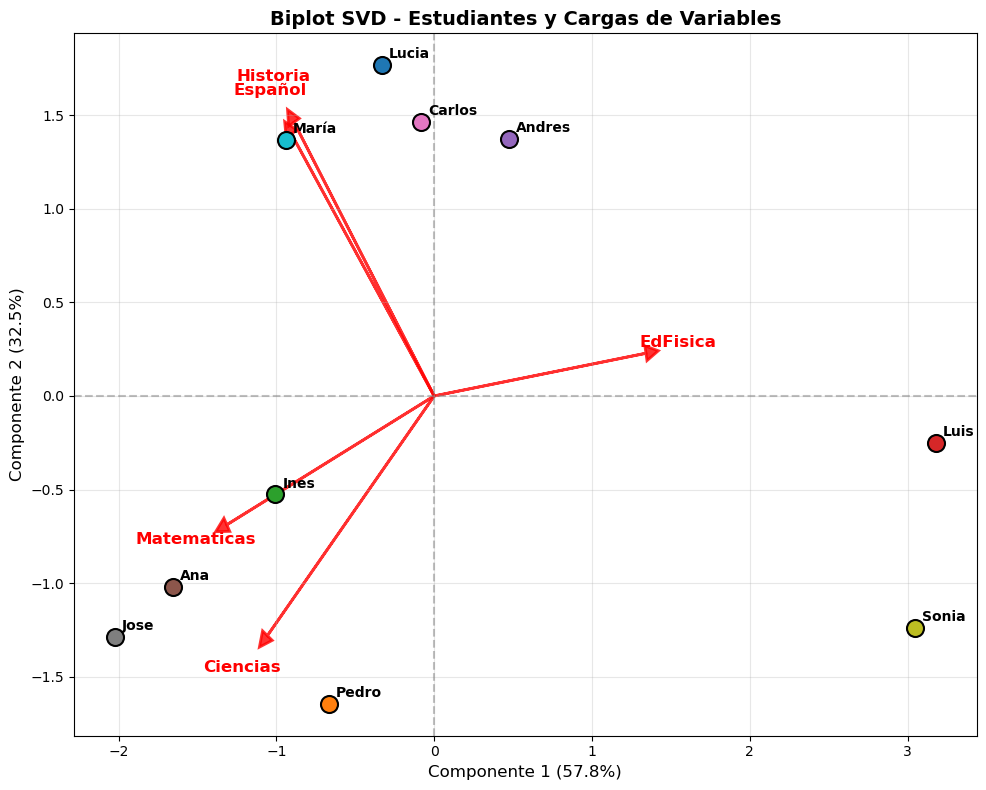

In [9]:
fig, ax = plt.subplots(figsize=(10, 8))

# Puntos (estudiantes)
for i, name in enumerate(df.index):
    ax.scatter(X_svd2[i, 0], X_svd2[i, 1], c=[colors[i]], s=150, edgecolors='black', linewidth=1.5, zorder=3)
    ax.annotate(name, (X_svd2[i, 0], X_svd2[i, 1]), 
                xytext=(5, 5), textcoords='offset points', fontsize=10, fontweight='bold')

# Flechas (cargas)
scale = 2.5
for j, col in enumerate(df.columns):
    ax.arrow(0, 0, components_svd.iloc[j, 0]*scale, components_svd.iloc[j, 1]*scale,
             head_width=0.08, head_length=0.08, fc='red', ec='red', linewidth=2, alpha=0.8)
    ax.text(components_svd.iloc[j, 0]*scale*1.15, components_svd.iloc[j, 1]*scale*1.15, 
            col, color='red', fontsize=12, fontweight='bold', ha='center')

ax.set_xlabel(f'Componente 1 ({svd_2.explained_variance_ratio_[0]*100:.1f}%)', fontsize=12)
ax.set_ylabel(f'Componente 2 ({svd_2.explained_variance_ratio_[1]*100:.1f}%)', fontsize=12)
ax.set_title('Biplot SVD - Estudiantes y Cargas de Variables', fontsize=14, fontweight='bold')
ax.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
ax.axvline(x=0, color='gray', linestyle='--', alpha=0.5)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Interpretación de Resultados y Respuestas a las Preguntas

### ¿Cuál separación es más clara: 2D o 3D?

**La separación en 2D es más clara y suficiente.** Los dos primeros componentes de SVD explican el **90.37%** de la varianza total, lo cual es muy alto. Al agregar una tercera dimensión se llega al **97.33%**, pero la mejora en separación visual es marginal. En el espacio 2D ya se distinguen claramente los grupos:

- **Grupo superior (alto en Español e Historia):** Lucía, Carlos, Andrés, María
- **Grupo izquierdo (alto en Matemáticas y Ciencias):** José, Ana, Pedro, Inés
- **Grupo derecho (alto en EdFísica):** Luis, Sonia

En 3D, Luis y Sonia se separan más claramente en la tercera dimensión, pero la estructura general de grupos ya estaba bien definida en 2D.

### ¿Difieren los resultados de SVD respecto a PCA?

**No, los resultados son idénticos.** Tanto en varianza explicada, cargas de variables, como en las proyecciones de los estudiantes, SVD y PCA producen exactamente los mismos valores. Esto se debe a que:

1. **PCA** se basa en la descomposición eigendecomposition de la matriz de covarianza.
2. **SVD** descompone directamente la matriz de datos estandarizados.
3. Cuando los datos están **centrados** (media cero), ambos métodos son matemáticamente equivalentes.

La única diferencia conceptual es que SVD es más general (funciona también con matrices no cuadradas y sin centrar), mientras que PCA asume centrado de datos. En este caso, al haber estandarizado previamente, ambos coinciden perfectamente.

### Resumen de hallazgos:

| Método | 2D Var. Acumulada | 3D Var. Acumulada | ¿Separa grupos? |
|--------|-------------------|-------------------|------------------|
| SVD    | 90.37%            | 97.33%            | Sí, claramente   |
| PCA    | 90.37%            | 97.33%            | Sí, claramente   |

**Conclusión:** Para este dataset de 10 estudiantes y 5 materias, la reducción a **2 dimensiones mediante SVD** es óptima. Es matemáticamente equivalente a PCA, por lo que cualquiera de los dos métodos produce el mismo agrupamiento de estudiantes según sus perfiles académicos.